# Validation: `hblteuk.jax` radial solver vs CPU reference

Visual companion to `tests/test_jax_teuk.py`. Sections **assert** their
checks; a clean top-to-bottom run is itself a regression test.

Three-way comparison: JAX batch vs the CPU fixed-domain solver on identical
subdomains (should agree to LU roundoff) and vs the committed golden data
(adaptive-solver reference).

In [1]:
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import jax.numpy as jnp

from hblteuk.geo import MiniGeo
from hblteuk import collocode
from hblteuk.collocode import generate_subdomain_list
from hblteuk.teuk import HyperboloidalTeukolskySolver, sigma_r
from hblteuk.swsh import swsh_eigenvalue
from hblteuk.jax import solve_homogeneous_batch, evaluate_multidomain
from hblteuk.jax.teukolsky import teuk_pqu

C = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
golden = np.load(pathlib.Path("..") / "tests" / "golden" / "golden_v1.npz")

orbit = MiniGeo(0.9, 10.0, 0.2, 1.0)   # golden-data orbit (eccentric)
a = orbit.a
kappa = np.sqrt(1 - a**2)
smin = sigma_r(orbit.radial_roots[0], kappa)
smax = sigma_r(orbit.radial_roots[1], kappa)
subs_up = generate_subdomain_list([0, smax], 150, "arcsinh7")
subs_in = generate_subdomain_list([1, smin], 150, "arcsinh7")

MODES = [(2, 2, 0), (3, 1, 0), (10, 7, 0), (2, 2, 3)]
omega = np.array([orbit.mode_frequency(m, 0, n) for _, m, n in MODES])
lam = np.array([swsh_eigenvalue(-2, l, m, a * w)
                for (l, m, _), w in zip(MODES, omega)])
ma = np.array([m * a for _, m, _ in MODES])
res = solve_homogeneous_batch(-2, kappa, lam, ma, omega, subs_up, subs_in, n=32)
print("batch solved:", res.coeffs_up.shape, res.coeffs_in.shape)

batch solved: (4, 150, 32) (4, 150, 32)


## 1. Against the CPU solver on identical subdomains

Same fixed structure, same boundary conditions — the only difference is the
LU implementation (XLA vs LAPACK). Agreement is limited by roundoff drift
accumulated across the 150-domain march.

worst relative difference over modes/derivs 0-2: 5.36e-09


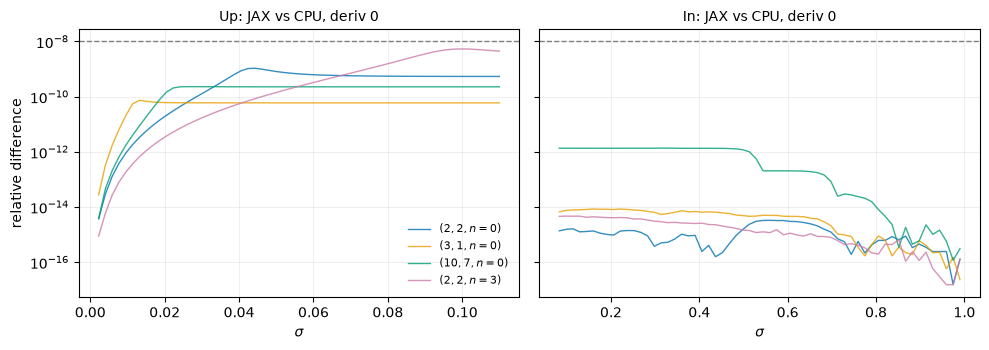

In [2]:
solver = collocode.CollocationODEFixedMultiDomainFixedStepSolver(n=32)
ts = HyperboloidalTeukolskySolver(
    domains=[[0, smax], [smin, 1]], solver=solver,
    subdomains={"Up": subs_up, "In": subs_in})
cpu = [ts(a, -2, l, m, omega[b], eigenvalue=lam[b])
       for b, (l, m, _) in enumerate(MODES)]

sig_up = np.linspace(0.02 * smax, 0.98 * smax, 60)
sig_in = np.linspace(smin + 0.01, 0.99, 60)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
worst = 0.0
for tag, coeffs, sub, sig, ax in [("Up", res.coeffs_up, subs_up, sig_up, axes[0]),
                                  ("In", res.coeffs_in, subs_in, sig_in, axes[1])]:
    for d in (0, 1, 2):
        got = np.asarray(evaluate_multidomain(coeffs, sub, sig, deriv=d))
        for b, hbl in enumerate(cpu):
            want = hbl.psi[tag](sig, deriv=d)
            rel = np.abs(got[b] - want) / np.abs(want)
            worst = max(worst, rel.max())
            if d == 0:
                ax.semilogy(sig, np.maximum(rel, 1e-17), lw=1,
                            color=C[b % 4], alpha=0.8,
                            label=rf"$({MODES[b][0]},{MODES[b][1]},n={MODES[b][2]})$" )
    ax.axhline(1e-8, ls="--", c="0.5", lw=1)
    ax.set_title(f"{tag}: JAX vs CPU, deriv 0", fontsize=10)
    ax.set_xlabel(r"$\sigma$")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("relative difference")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
assert worst < 1e-8
print(f"worst relative difference over modes/derivs 0-2: {worst:.2e}")

## 2. Roundoff-drift anatomy

Per-domain coefficient difference between JAX and CPU along the Up march:
starts at machine epsilon and grows smoothly as LU roundoff differences are
amplified by the recursion — the signature that both solvers track the same
solution (a bug would jump, not drift).

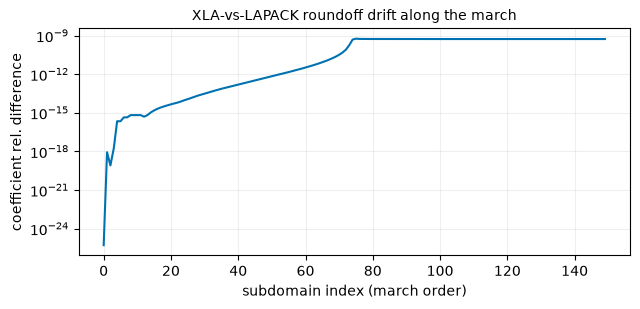

In [3]:
from hblteuk.teuk import teuk_sys, boundary_condition_up
b = 0  # (2,2,0)
bc = boundary_condition_up(kappa, -2, lam[b], ma[b], omega[b])
sol = solver(teuk_sys, list(bc),
             args=(kappa, -2, complex(lam[b]), ma[b], complex(omega[b])),
             domain=[0, smax], subdomains=subs_up)
c_cpu = sol.coeffs
c_jax = np.asarray(res.coeffs_up[b])
drift = [np.max(np.abs(c_jax[d] - c_cpu[d])) / np.max(np.abs(c_cpu[d]))
         for d in range(c_cpu.shape[0])]

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.semilogy(np.maximum(drift, 1e-30), lw=1.5, color=C[0])
ax.set_xlabel("subdomain index (march order)")
ax.set_ylabel("coefficient rel. difference")
ax.set_title("XLA-vs-LAPACK roundoff drift along the march", fontsize=10)
ax.grid(alpha=0.2)
plt.tight_layout()
assert drift[0] < 1e-15 and max(drift) < 1e-8

## 3. ODE residual and boundary conditions

Physics checks that are independent of any reference implementation.

In [4]:
worst_ode = 0.0
for coeffs, sub, sig in [(res.coeffs_up, subs_up, sig_up),
                         (res.coeffs_in, subs_in, sig_in)]:
    psi = np.asarray(evaluate_multidomain(coeffs, sub, sig))
    dpsi = np.asarray(evaluate_multidomain(coeffs, sub, sig, deriv=1))
    d2psi = np.asarray(evaluate_multidomain(coeffs, sub, sig, deriv=2))
    P, Q, U = teuk_pqu(jnp.asarray(sig), kappa, -2,
                       jnp.asarray(lam, dtype=jnp.complex128), jnp.asarray(ma),
                       jnp.asarray(omega, dtype=jnp.complex128))
    P, Q, U = np.asarray(P), np.asarray(Q), np.asarray(U)
    resid = np.abs(P * d2psi + Q * dpsi + U * psi)
    scale = np.abs(P * d2psi) + np.abs(Q * dpsi) + np.abs(U * psi)
    worst_ode = max(worst_ode, np.max(resid / scale))
assert worst_ode < 1e-8
print(f"worst normalized ODE residual: {worst_ode:.2e}")

for coeffs, sub, sb in [(res.coeffs_up, subs_up, 0.0),
                        (res.coeffs_in, subs_in, 1.0)]:
    psi = np.asarray(evaluate_multidomain(coeffs, sub, np.array([sb])))[:, 0]
    dpsi = np.asarray(evaluate_multidomain(coeffs, sub, np.array([sb]),
                                           deriv=1))[:, 0]
    _, Q, U = teuk_pqu(jnp.array([sb]), kappa, -2,
                       jnp.asarray(lam, dtype=jnp.complex128), jnp.asarray(ma),
                       jnp.asarray(omega, dtype=jnp.complex128))
    ratio = -np.asarray(U)[:, 0] / np.asarray(Q)[:, 0]
    err = np.max(np.abs(dpsi / psi - ratio) / np.abs(ratio))
    assert err < 1e-9
    print(f"BC at sigma = {sb}: max rel error {err:.2e}")

worst normalized ODE residual: 2.95e-13


BC at sigma = 0.0: max rel error 8.67e-16
BC at sigma = 1.0: max rel error 5.42e-16


## 4. Golden-file comparison

The golden data used per-mode *adaptive* subdomains, so agreement is gated
at the fixed-vs-dynamic level (the march's accuracy is absolute relative to
the domain peak — $\psi''$ spans ~10 decades on the In side).

In [5]:
worst_g = 0.0
for i in range(4):
    for tag, coeffs, sub in [("up", res.coeffs_up, subs_up),
                             ("in", res.coeffs_in, subs_in)]:
        sig = golden[f"hom{i}_sig_{tag}"]
        for d in (0, 1, 2):
            got = np.asarray(evaluate_multidomain(coeffs, sub, sig, deriv=d))[i]
            want = golden[f"hom{i}_psi_{tag}_d{d}"]
            err = np.max(np.abs(got - want) / np.max(np.abs(want)))
            worst_g = max(worst_g, err)
            assert err < 1e-7, (i, tag, d)
print(f"worst peak-scaled deviation from golden: {worst_g:.2e}")

worst peak-scaled deviation from golden: 2.85e-09


## Summary

1. JAX ≡ CPU fixed-domain solver to ≤ 1e-8 (roundoff drift, not systematic)
2. drift anatomy confirms same-solution tracking
3. ODE residual < 1e-8 and boundary conditions exact to 1e-9 — reference-free
4. golden (adaptive) data reproduced at the fixed-vs-dynamic gate

`pytest tests/ -q` remains the canonical gate. Note: chasing the original
golden mismatch here uncovered (and fixed) a real CPU bug — descending-domain
`MultiDomainChebyshev.derivn` paired coefficients with the wrong domain
widths; see `dev/PHASE2.md`.